In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.dummy import DummyRegressor
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
OUT = ROOT / "outputs"
OUT.mkdir(exist_ok=True)
sns.set_theme(style="whitegrid")

df = pd.read_csv(ROOT / "data" / "Cleaned" / "city_day_regression.csv", parse_dates=["Date"])

POLL = ["PM2.5", "PM10", "NO", "NO2", "NOx", "NH3", "CO", "SO2", "O3", "Benzene", "Toluene"]
DATE_NUM = ["Month", "Weekday", "Is_Weekend", "Is_Winter", "Is_Diwali_Period"]

# Season and City are text, so convert them to 0/1 columns
X = pd.concat(
    [df[POLL + DATE_NUM], pd.get_dummies(df[["Season", "City"]], dtype=int)],
    axis=1,
)
y = df["AQI"]

train = df["Split"] == "Train"
X_train, X_test = X[train], X[~train]
y_train, y_test = y[train], y[~train]

print("Features:", X.shape[1])
print("Train rows:", len(X_train), "| Test rows:", len(X_test))

Features: 46
Train rows: 13326 | Test rows: 11475


Load data and pick features

In [2]:
models = {
    "Baseline (predict mean)": DummyRegressor(strategy="mean"),
    "Linear Regression": make_pipeline(StandardScaler(), LinearRegression()),
    "Decision Tree": DecisionTreeRegressor(max_depth=10, random_state=42),
    "Random Forest": RandomForestRegressor(n_estimators=200, n_jobs=-1, random_state=42),
}

rows, preds = [], {}
for name, model in models.items():
    model.fit(X_train, y_train)
    pred = model.predict(X_test)
    preds[name] = pred
    rows.append({
        "Model": name,
        "MAE": mean_absolute_error(y_test, pred),
        "RMSE": np.sqrt(mean_squared_error(y_test, pred)),
        "R2": r2_score(y_test, pred),
    })

results = pd.DataFrame(rows).round(3)
results.to_csv(OUT / "regression_results.csv", index=False)
results

,Model,MAE,RMSE,R2
0,Baseline (predict mean),102.224,130.034,-0.169
1,Linear Regression,27.802,45.866,0.855
2,Decision Tree,23.812,50.536,0.823
3,Random Forest,19.961,41.165,0.883


Training and scoring

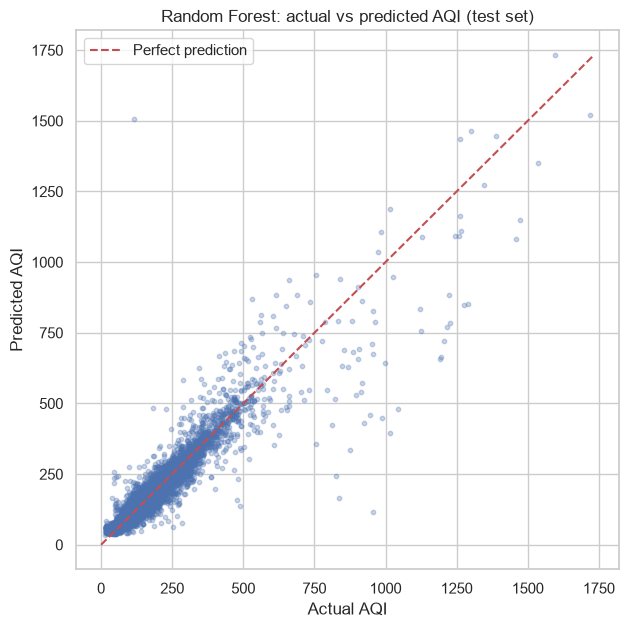

In [3]:
fig, ax = plt.subplots(figsize=(7, 7))
ax.scatter(y_test, preds["Random Forest"], alpha=0.3, s=10)
lim = [0, max(y_test.max(), preds["Random Forest"].max())]
ax.plot(lim, lim, "r--", label="Perfect prediction")
ax.set_xlabel("Actual AQI")
ax.set_ylabel("Predicted AQI")
ax.set_title("Random Forest: actual vs predicted AQI (test set)")
ax.legend()
plt.savefig(OUT / "10_rf_actual_vs_predicted.png", dpi=150, bbox_inches="tight")
plt.show()

Actual vs predicted (Random Forest)

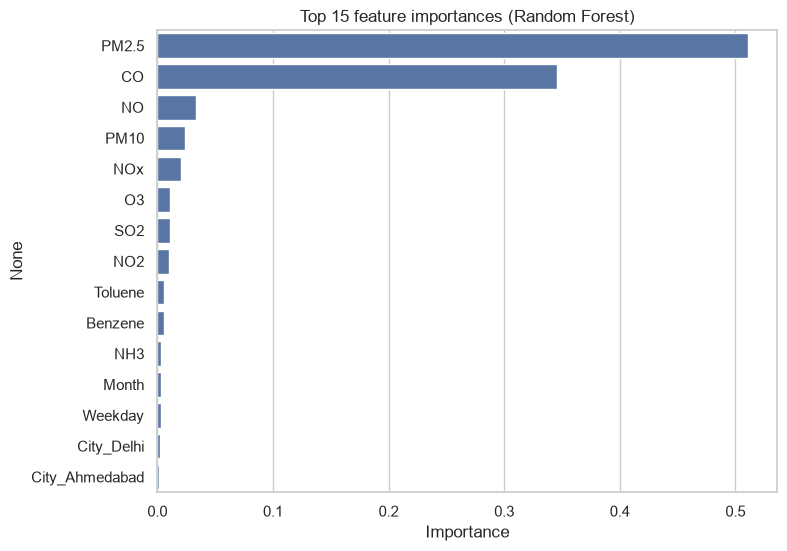

In [4]:
rf = models["Random Forest"]
imp = pd.Series(rf.feature_importances_, index=X.columns).sort_values(ascending=False).head(15)

plt.figure(figsize=(8, 6))
sns.barplot(x=imp.values, y=imp.index)
plt.title("Top 15 feature importances (Random Forest)")
plt.xlabel("Importance")
plt.savefig(OUT / "11_rf_feature_importance.png", dpi=150, bbox_inches="tight")
plt.show()

Feature importance

In [5]:
top_features = list(imp.head(8).index)

rf_small = RandomForestRegressor(n_estimators=200, n_jobs=-1, random_state=42)
rf_small.fit(X_train[top_features], y_train)
pred_small = rf_small.predict(X_test[top_features])

print("Using only:", top_features)
print("MAE :", round(mean_absolute_error(y_test, pred_small), 2))
print("RMSE:", round(np.sqrt(mean_squared_error(y_test, pred_small)), 2))
print("R2  :", round(r2_score(y_test, pred_small), 3))

Using only: ['PM2.5', 'CO', 'NO', 'PM10', 'NOx', 'O3', 'SO2', 'NO2']
MAE : 20.85
RMSE: 42.32
R2  : 0.876


Does a smaller feature set do as well?